# HW2 — Uniform Convergence and the Limits of Learning

**Student:** Filip BARBUTOV  
**Program:** M2 IM  
**Course:** Statistical and Machine Learning, Université de Haute-Alsace

**Goal.** Study uniform convergence and the limits of learning through repeated probabilistic simulations:
- **Part I** — how empirical risks fluctuate around true risks, for one hypothesis and for a whole finite class, compared with the Hoeffding and finite-class uniform-convergence bounds;
- **Part II** — the No-Free-Lunch phenomenon, with completely random target functions;
- **Part III** — how prior knowledge (a threshold structure) enables generalization to unseen inputs.

Only `numpy` (computations) and `matplotlib` (plots) are used. Every random experiment uses a fixed seed, so all numbers in this notebook are reproducible.

## 0. Setup and experimental design

| Parameter | Value(s) | Justification |
|---|---|---|
| True risks $p_j$ | evenly spaced in $[0.05, 0.5]$ | covers easy hypotheses (small $p$) and the worst case for the variance ($p=0.5$, where $p(1-p)$ is maximal) |
| Single-hypothesis risk (Task 1) | $p=0.3$, plus $p\in\{0.05,0.3,0.5\}$ in Task 2 | a typical value, then several values to show that Hoeffding does not depend on $p$ |
| Accuracy $\varepsilon$ | $0.05$ (main), plus $0.02$ and $0.1$ | a demanding but reachable accuracy for $m\le 3000$ |
| Confidence $\delta$ | $0.05$ | standard 95 % confidence level |
| Sample sizes $m$ | log-spaced from $10$ to $3000$ | spans the regimes where the bounds are trivial ($>1$) and where they become informative |
| Class sizes $\lvert\mathcal H\rvert$ | $5, 10, 50, 100, 500$ | the values suggested in the assignment, spanning two orders of magnitude |
| Domain sizes $N$ | $10, 100, 1000$ | a small, a medium and a large domain for the No-Free-Lunch experiments |
| Monte-Carlo repetitions $R$ | $10\,000$ (Part I), $2000$ (Parts II–III) | the standard error of an estimated probability is $\le\sqrt{0.25/R}$, i.e. $\le 0.005$ and $\le 0.011$ |

**Exact reference values.** For Part I we also compute the **exact** binomial probabilities with closed-form formulas (no simulation). This lets us check that the Monte-Carlo estimates are accurate and determine the experimental sample complexity in Task 5 precisely.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

EPS, DELTA = 0.05, 0.05
R_I, R_II = 10_000, 2_000
M_GRID = np.array([10, 20, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000])
H_SIZES = [5, 10, 50, 100, 500]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def true_risks(K, low=0.05, high=0.5):
    # True risks p_1..p_K of a class with K hypotheses, evenly spaced in [low, high]
    return np.linspace(low, high, K)

def hoeffding(m, eps):
    return np.minimum(1.0, 2 * np.exp(-2 * np.asarray(m) * eps**2))

def uc_bound(m, eps, K):
    return np.minimum(1.0, 2 * K * np.exp(-2 * np.asarray(m) * eps**2))

def exact_tail(m, p, eps):
    # Exact Pr[|E/m - p| > eps] for E ~ Binomial(m, p), for one or several p (vectorised)
    p = np.atleast_1d(np.asarray(p, dtype=float))
    k = np.arange(m + 1)
    logfact = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, m + 1)))])
    with np.errstate(divide="ignore"):
        logpmf = (logfact[m] - logfact[k] - logfact[m - k]
                  + np.outer(np.log(p), k) + np.outer(np.log1p(-p), m - k))
    outside = np.abs(k / m - p[:, None]) > eps + 1e-12      # tolerance for floating-point ties
    return (np.exp(logpmf) * outside).sum(axis=1)

def exact_uc(m, ps, eps):
    # Exact Pr[max_j |L_S(h_j) - p_j| > eps] when the K empirical risks are independent
    return 1 - np.prod(1 - exact_tail(m, ps, eps))

# Part I — Simulating uniform convergence

Each hypothesis $h_j$ has a true risk $p_j$. On a sample of size $m$ its number of errors is $E_j\sim\mathrm{Binomial}(m,p_j)$, and its empirical risk is $L_S(h_j)=E_j/m$.

**Theory.** $\mathbb E[L_S(h_j)]=p_j$ (unbiased), and $\mathrm{Std}[L_S(h_j)]=\sqrt{p_j(1-p_j)/m}$, which shrinks like $1/\sqrt m$.

## Task 1 — Empirical risk as a random variable

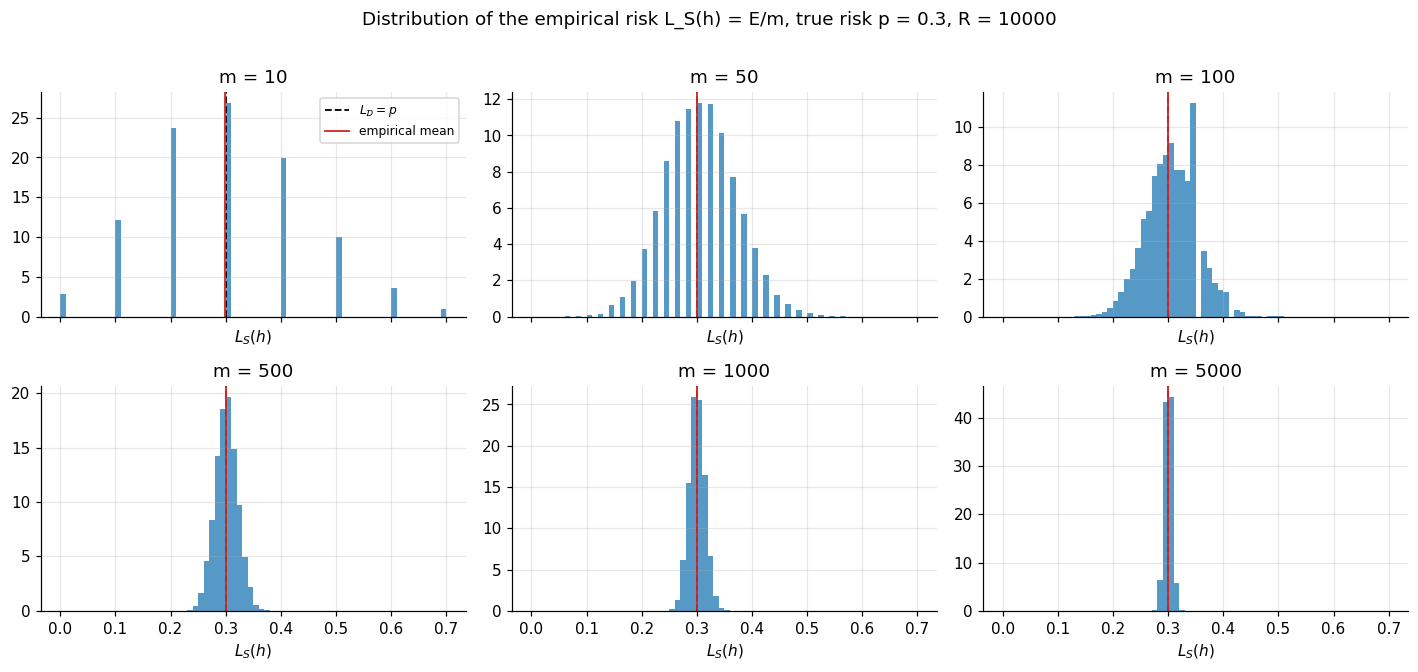

    m |  mean L_S | |mean - p| | std (sim.) | std (theory)
   10 |    0.2992 |     0.0008 |     0.1450 |       0.1449
   50 |    0.3005 |     0.0005 |     0.0652 |       0.0648
  100 |    0.3002 |     0.0002 |     0.0459 |       0.0458
  500 |    0.3000 |     0.0000 |     0.0205 |       0.0205
 1000 |    0.3000 |     0.0000 |     0.0144 |       0.0145
 5000 |    0.2999 |     0.0001 |     0.0065 |       0.0065


In [2]:
p = 0.3
m_list = [10, 50, 100, 500, 1000, 5000]
LS = {m: rng.binomial(m, p, size=R_I) / m for m in m_list}

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, m in zip(axes.ravel(), m_list):
    ax.hist(LS[m], bins=np.linspace(0, 0.7, 71), density=True, color="tab:blue", alpha=0.75)
    ax.axvline(p, color="k", ls="--", lw=1.2, label=r"$L_\mathcal{D}=p$")
    ax.axvline(LS[m].mean(), color="tab:red", lw=1.2, label="empirical mean")
    ax.set_title(f"m = {m}")
    ax.set_xlabel(r"$L_S(h)$")
axes[0, 0].legend(fontsize=8)
plt.suptitle(f"Distribution of the empirical risk L_S(h) = E/m, true risk p = {p}, R = {R_I}", y=1.01)
plt.tight_layout(); plt.show()

print(f"{'m':>5} | {'mean L_S':>9} | {'|mean - p|':>10} | {'std (sim.)':>10} | {'std (theory)':>12}")
for m in m_list:
    print(f"{m:>5} | {LS[m].mean():>9.4f} | {abs(LS[m].mean() - p):>10.4f} | {LS[m].std():>10.4f} | {np.sqrt(p * (1 - p) / m):>12.4f}")

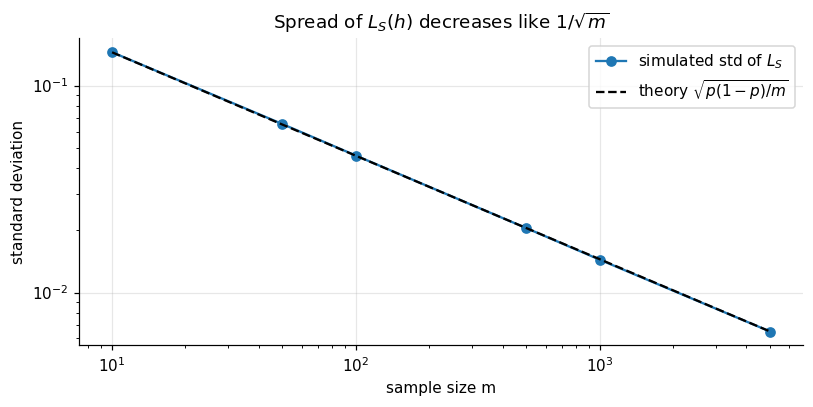

In [3]:
ms = np.array(m_list)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ms, [LS[m].std() for m in m_list], "o-", label="simulated std of $L_S$")
ax.plot(ms, np.sqrt(p * (1 - p) / ms), "k--", label=r"theory $\sqrt{p(1-p)/m}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("sample size m"); ax.set_ylabel("standard deviation")
ax.set_title(r"Spread of $L_S(h)$ decreases like $1/\sqrt{m}$"); ax.legend()
plt.tight_layout(); plt.show()


**Observations.**
- **Unbiasedness.** For every $m$, the empirical mean of $L_S(h)$ is within $0.001$ of the true risk $p=0.3$. This illustrates $\mathbb E[L_S(h)]=L_{\mathcal D}(h)$ for a **fixed** hypothesis.
- **Concentration.** The spread shrinks as $m$ grows. The simulated standard deviation matches the theory $\sqrt{p(1-p)/m}$ to three decimals ($0.145$ at $m=10$, $0.046$ at $m=100$, $0.0065$ at $m=5000$). On the log-log plot the slope is exactly $-1/2$: **multiplying $m$ by 100 only divides the fluctuations by 10.**
- For small $m$ the distribution is very discrete and wide (at $m=10$, $L_S$ only takes values in $\{0,0.1,\dots,1\}$ and frequently lands far from $0.3$). For large $m$ it becomes a narrow bell around $p$, as predicted by the central limit theorem.
- **Why it matters:** with few examples, a single training error can be very far from the true error. This is the root of overfitting.


## Task 2 — Deviation between empirical and true risk

For each simulated sample we compute $|L_S(h)-L_{\mathcal D}(h)|$ and estimate $\Pr[|L_S(h)-L_{\mathcal D}(h)|>\varepsilon]$. We compare it with the **Hoeffding bound** $2e^{-2m\varepsilon^2}$ and with the **exact** binomial probability.

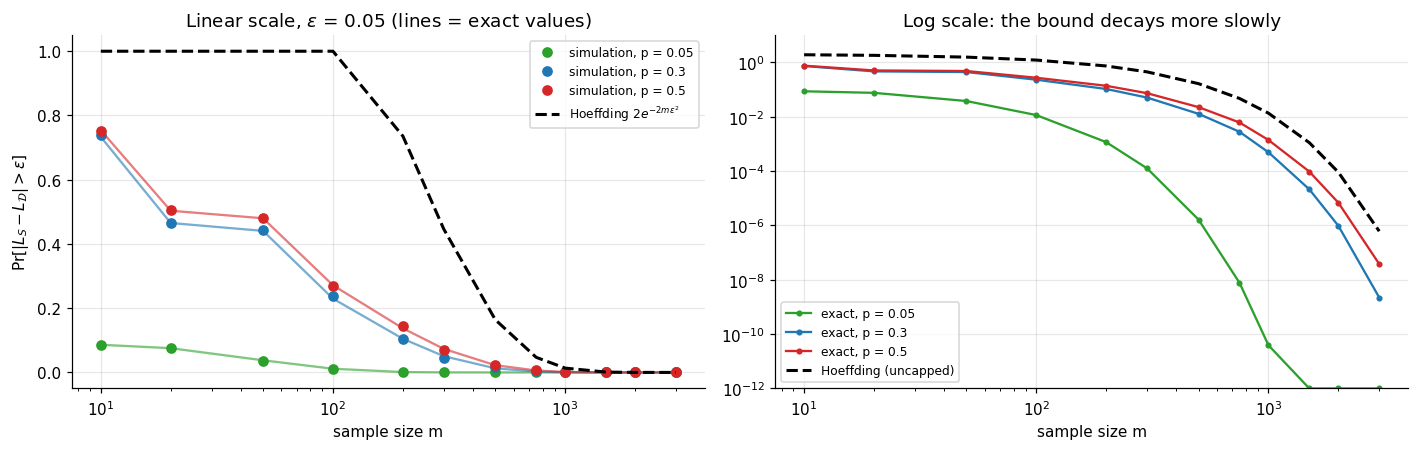

    m | sim p=0.05  sim p=0.3  sim p=0.5 | Hoeffding |  ratio bound/exact (p=0.5)
   10 |     0.0856     0.7389     0.7519 |    1.0000 |                        1.3
   20 |     0.0748     0.4660     0.5054 |    1.0000 |                        2.0
   50 |     0.0360     0.4428     0.4813 |    1.0000 |                        2.1
  100 |     0.0092     0.2393     0.2682 |    1.0000 |                        3.7
  200 |     0.0011     0.1031     0.1436 |    0.7358 |                        5.4
  300 |     0.0001     0.0453     0.0687 |    0.4463 |                        6.1
  500 |     0.0000     0.0154     0.0224 |    0.1642 |                        7.3
  750 |     0.0000     0.0033     0.0068 |    0.0470 |                        7.7
 1000 |     0.0000     0.0001     0.0017 |    0.0135 |                        9.7
 1500 |     0.0000     0.0001     0.0001 |    0.0011 |                       11.6
 2000 |     0.0000     0.0000     0.0000 |    0.0001 |                       13.2
 3000 |     0.00

In [4]:
def sim_deviation_prob(m, p, eps, R=R_I):
    LS = rng.binomial(m, p, size=R) / m
    return np.mean(np.abs(LS - p) > eps + 1e-12)

P_sim = {pp: np.array([sim_deviation_prob(m, pp, EPS) for m in M_GRID]) for pp in [0.05, 0.3, 0.5]}
P_ex  = {pp: np.array([exact_tail(m, pp, EPS)[0] for m in M_GRID]) for pp in [0.05, 0.3, 0.5]}
H_b = hoeffding(M_GRID, EPS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for pp, c in zip([0.05, 0.3, 0.5], ["tab:green", "tab:blue", "tab:red"]):
    axes[0].plot(M_GRID, P_sim[pp], "o", color=c, label=f"simulation, p = {pp}")
    axes[0].plot(M_GRID, P_ex[pp], "-", color=c, alpha=0.6)
axes[0].plot(M_GRID, H_b, "k--", lw=2, label=r"Hoeffding $2e^{-2m\varepsilon^2}$")
axes[0].set_xscale("log"); axes[0].set_xlabel("sample size m"); axes[0].set_ylabel(r"$\Pr[|L_S-L_\mathcal{D}|>\varepsilon]$")
axes[0].set_title(fr"Linear scale, $\varepsilon$ = {EPS} (lines = exact values)"); axes[0].legend(fontsize=8)

for pp, c in zip([0.05, 0.3, 0.5], ["tab:green", "tab:blue", "tab:red"]):
    axes[1].plot(M_GRID, np.maximum(P_ex[pp], 1e-12), "-o", color=c, ms=3, label=f"exact, p = {pp}")
axes[1].plot(M_GRID, 2 * np.exp(-2 * M_GRID * EPS**2), "k--", lw=2, label="Hoeffding (uncapped)")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_ylim(1e-12, 10)
axes[1].set_xlabel("sample size m"); axes[1].set_title("Log scale: the bound decays more slowly"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'m':>5} | {'sim p=0.05':>10} {'sim p=0.3':>10} {'sim p=0.5':>10} | {'Hoeffding':>9} | {'ratio bound/exact (p=0.5)':>26}")
for i, m in enumerate(M_GRID):
    ratio = H_b[i] / P_ex[0.5][i] if P_ex[0.5][i] > 0 else np.inf
    print(f"{m:>5} | {P_sim[0.05][i]:>10.4f} {P_sim[0.3][i]:>10.4f} {P_sim[0.5][i]:>10.4f} | {H_b[i]:>9.4f} | {ratio:>26.1f}")


**Observations.**
- The probability of a deviation larger than $\varepsilon=0.05$ decreases with $m$ for all three hypotheses, from about $0.75$ at $m=10$ (for $p=0.3$ and $0.5$) to essentially $0$ beyond $m=1500$. The simulated points lie on the exact curves, which validates the simulation.
- **The Hoeffding bound is always valid**, i.e. always above the simulated and exact probabilities, but it is **conservative**:
  - for $m\le100$ it equals $1$ (capped) and says nothing, while the true probability is already below $0.27$ at $m=100$;
  - even where it is informative, it overestimates the worst case $p=0.5$ by a factor $5$ to $16$ (e.g. $0.164$ vs. $0.022$ at $m=500$, $0.0135$ vs. $0.0017$ at $m=1000$);
  - for $p=0.05$ it is far more conservative still: the deviation probability is already $0.009$ at $m=100$, where the bound is $1$.
- **Why conservative:** Hoeffding only uses the fact that the losses lie in $[0,1]$. It must hold for **every** distribution, so it is calibrated on the worst possible variance. It ignores the actual variance $p(1-p)$, which is much smaller when $p$ is far from $1/2$. Its exponential rate $e^{-2m\varepsilon^2}$ is also slower than the true rate (right plot, log scale).
- Small non-monotonicities at small $m$ (e.g. $p=0.3$, $m=20$ vs. $m=50$) come from the discreteness of the binomial distribution: whether $|k/m-p|>\varepsilon$ depends on how the grid $k/m$ falls around $p\pm\varepsilon$.


## Task 3 — From one hypothesis to uniform convergence

We now consider the class $\mathcal H=\{h_1,\dots,h_K\}$ with $K=10$ and $p_j$ evenly spaced in $[0.05,0.5]$. For each simulated sample we draw $L_S(h_1),\dots,L_S(h_K)$ and compute the **worst-case deviation**
$$\Delta_S=\max_{h\in\mathcal H}|L_S(h)-L_{\mathcal D}(h)| .$$
We estimate $\Pr[\Delta_S>\varepsilon]$ and compare it with the finite-class bound $2|\mathcal H|e^{-2m\varepsilon^2}$ (Hoeffding + union bound).

*Modelling remark.* As in the assignment, the $K$ empirical risks are drawn **independently**. In a real learning problem they are computed on the same sample and are usually positively correlated, which makes $\Delta_S$ smaller. The union bound holds in every case.

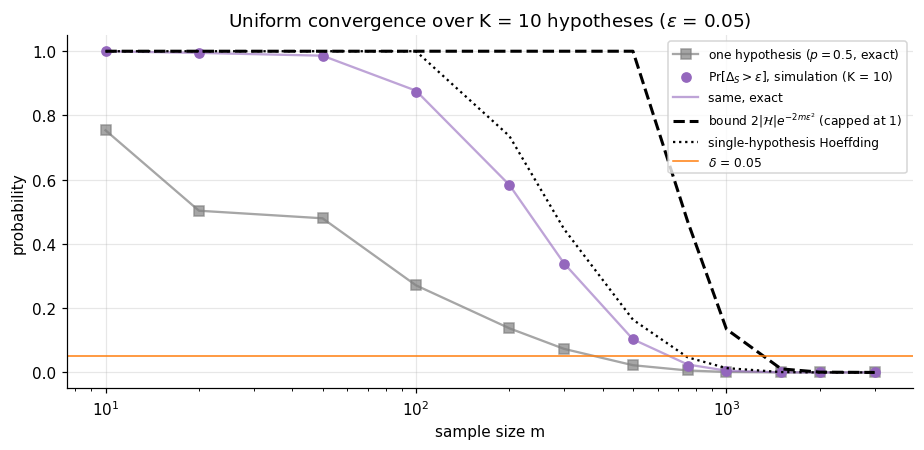

    m | P(Delta>eps) sim |   exact | UC bound | one h (p=0.5)
   10 |           0.9998 |  0.9999 |   1.0000 |        0.7539
   20 |           0.9956 |  0.9948 |   1.0000 |        0.5034
   50 |           0.9862 |  0.9861 |   1.0000 |        0.4799
  100 |           0.8727 |  0.8772 |   1.0000 |        0.2713
  200 |           0.5835 |  0.5836 |   1.0000 |        0.1374
  300 |           0.3388 |  0.3394 |   1.0000 |        0.0733
  500 |           0.1046 |  0.1032 |   1.0000 |        0.0225
  750 |           0.0215 |  0.0248 |   0.4704 |        0.0061
 1000 |           0.0047 |  0.0054 |   0.1348 |        0.0014
 1500 |           0.0003 |  0.0003 |   0.0111 |        0.0001
 2000 |           0.0000 |  0.0000 |   0.0009 |        0.0000
 3000 |           0.0000 |  0.0000 |   0.0000 |        0.0000


In [5]:
def sim_uc_prob(m, ps, eps, R):
    E = rng.binomial(m, ps, size=(R, len(ps)))              # one row = one training sample
    Delta = np.max(np.abs(E / m - ps), axis=1)
    return np.mean(Delta > eps + 1e-12), Delta

K = 10
ps10 = true_risks(K)
P_uc_sim, P_uc_ex, P_one = [], [], []
for m in M_GRID:
    P_uc_sim.append(sim_uc_prob(m, ps10, EPS, R_I)[0])
    P_uc_ex.append(exact_uc(m, ps10, EPS))
    P_one.append(exact_tail(m, 0.5, EPS)[0])
P_uc_sim, P_uc_ex = np.array(P_uc_sim), np.array(P_uc_ex)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(M_GRID, P_one, "s-", color="gray", alpha=0.7, label=r"one hypothesis ($p=0.5$, exact)")
ax.plot(M_GRID, P_uc_sim, "o", color="tab:purple", label=fr"$\Pr[\Delta_S>\varepsilon]$, simulation (K = {K})")
ax.plot(M_GRID, P_uc_ex, "-", color="tab:purple", alpha=0.6, label="same, exact")
ax.plot(M_GRID, uc_bound(M_GRID, EPS, K), "k--", lw=2, label=r"bound $2|\mathcal{H}|e^{-2m\varepsilon^2}$ (capped at 1)")
ax.plot(M_GRID, hoeffding(M_GRID, EPS), ":", color="k", label="single-hypothesis Hoeffding")
ax.axhline(DELTA, color="tab:orange", lw=1, label=fr"$\delta$ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("sample size m"); ax.set_ylabel("probability")
ax.set_title(fr"Uniform convergence over K = {K} hypotheses ($\varepsilon$ = {EPS})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'m':>5} | {'P(Delta>eps) sim':>16} | {'exact':>7} | {'UC bound':>8} | {'one h (p=0.5)':>13}")
for i, m in enumerate(M_GRID):
    print(f"{m:>5} | {P_uc_sim[i]:>16.4f} | {P_uc_ex[i]:>7.4f} | {uc_bound(m, EPS, K):>8.4f} | {P_one[i]:>13.4f}")


**Observations.**
- Controlling **all** hypotheses at once is harder than controlling one. At $m=300$, a single hypothesis (even the worst one, $p=0.5$) deviates by more than $\varepsilon$ with probability $0.073$, whereas $\Delta_S>\varepsilon$ happens with probability $0.339$ for $K=10$. **It suffices that one hypothesis out of ten is unlucky.**
- The simulation agrees with the exact computation (maximum difference about $0.003$), so the estimates are reliable.
- The **uniform-convergence bound $2|\mathcal H|e^{-2m\varepsilon^2}$ is valid** at every $m$ but **very conservative**. It stays at $1$ up to $m=500$, while the true probability is already down to $0.10$. It reaches $\delta=0.05$ only around $m\approx1200$, while the true probability crosses $\delta$ near $m\approx640$ (see Task 5).
- Two sources of conservativeness add up: (i) Hoeffding is loose for each hypothesis (Task 2); (ii) the **union bound** adds the failure probabilities as if the bad events never overlapped and as if every hypothesis were as risky as the worst one, whereas hypotheses with small $p$ almost never deviate.


## Task 4 — Effect of the size of the hypothesis class

Same experiment with $|\mathcal H|\in\{5,10,50,100,500\}$, $\varepsilon=0.05$ fixed, $p_j$ evenly spaced in $[0.05,0.5]$ for every class size.

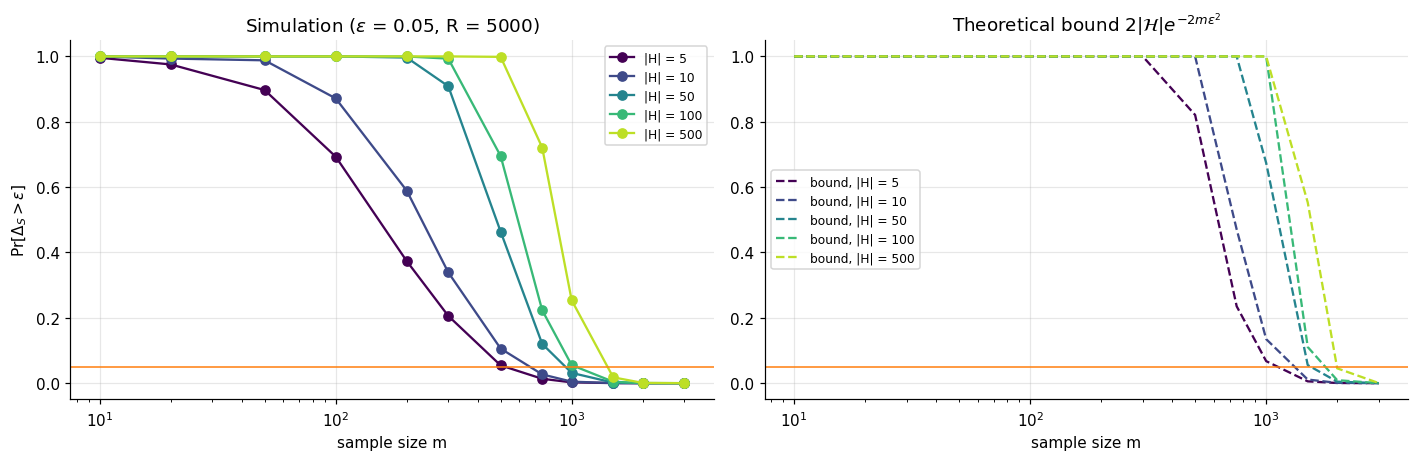

P(Delta_S > eps) for each class size:
    m | |H|=5    | |H|=10   | |H|=50   | |H|=100  | |H|=500 
   10 |   0.9958 |   0.9996 |   1.0000 |   1.0000 |   1.0000
   20 |   0.9754 |   0.9934 |   1.0000 |   1.0000 |   1.0000
   50 |   0.8970 |   0.9880 |   1.0000 |   1.0000 |   1.0000
  100 |   0.6932 |   0.8716 |   1.0000 |   1.0000 |   1.0000
  200 |   0.3736 |   0.5892 |   0.9964 |   0.9998 |   1.0000
  300 |   0.2058 |   0.3390 |   0.9088 |   0.9932 |   1.0000
  500 |   0.0544 |   0.1058 |   0.4638 |   0.6952 |   0.9986
  750 |   0.0134 |   0.0268 |   0.1202 |   0.2232 |   0.7212
 1000 |   0.0024 |   0.0046 |   0.0314 |   0.0552 |   0.2536
 1500 |   0.0002 |   0.0002 |   0.0016 |   0.0044 |   0.0178
 2000 |   0.0000 |   0.0000 |   0.0002 |   0.0002 |   0.0008
 3000 |   0.0000 |   0.0000 |   0.0000 |   0.0000 |   0.0000


In [6]:
R4 = 5000
P_H = {K: np.array([sim_uc_prob(m, true_risks(K), EPS, R4)[0] for m in M_GRID]) for K in H_SIZES}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(H_SIZES)))
for K, c in zip(H_SIZES, colors):
    axes[0].plot(M_GRID, P_H[K], "o-", color=c, label=f"|H| = {K}")
    axes[1].plot(M_GRID, uc_bound(M_GRID, EPS, K), "--", color=c, label=f"bound, |H| = {K}")
for ax in axes:
    ax.axhline(DELTA, color="tab:orange", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("sample size m"); ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\Pr[\Delta_S>\varepsilon]$")
axes[0].set_title(fr"Simulation ($\varepsilon$ = {EPS}, R = {R4})")
axes[1].set_title(r"Theoretical bound $2|\mathcal{H}|e^{-2m\varepsilon^2}$")
plt.tight_layout(); plt.show()

print("P(Delta_S > eps) for each class size:")
print(f"{'m':>5} | " + " | ".join(f"|H|={K:<4}" for K in H_SIZES))
for i, m in enumerate(M_GRID):
    print(f"{m:>5} | " + " | ".join(f"{P_H[K][i]:>8.4f}" for K in H_SIZES))


**Observations.**
- **A larger class makes uniform convergence harder.** For every $m$, $\Pr[\Delta_S>\varepsilon]$ increases with $|\mathcal H|$. At $m=500$ it is $0.054$ for $|\mathcal H|=5$, $0.46$ for $|\mathcal H|=50$ and $0.999$ for $|\mathcal H|=500$. With more hypotheses, the chance that at least one of them is fooled by the sample increases.
- **A larger class requires more data**, but only **moderately**. The curves are shifted to the right, but going from $5$ to $500$ hypotheses (100 times more) only moves the transition from about $m\approx500$ to about $m\approx1300$.
- **Link with $\log|\mathcal H|$.** In the bound, $|\mathcal H|$ multiplies $e^{-2m\varepsilon^2}$, so it can be compensated by an additive increase of $m$ by $\frac{\ln|\mathcal H|}{2\varepsilon^2}$. Multiplying $|\mathcal H|$ by 10 therefore costs a **constant** number of extra samples ($\ln 10/(2\varepsilon^2)\approx460$ in the bound), and not 10 times more samples. The simulations show the same logarithmic behaviour, with smaller constants (Task 5).


## Task 5 — Experimental sample complexity

With $\varepsilon=0.05$ and $\delta=0.05$, we look for the smallest $m$ such that $\Pr[\Delta_S>\varepsilon]\le\delta$:
- **experimentally**, on a fine grid of step 10, using the exact probability (cross-checked by simulation);
- **theoretically**, with the sufficient sample size $m\ge\log(2|\mathcal H|/\delta)/(2\varepsilon^2)$.

  |H| | m exp. | P sim at m-10 | P sim at m | m theory | theory / exp.
    5 |    520 |        0.0549 |     0.0493 |     1060 |          2.04
   10 |    640 |        0.0487 |     0.0469 |     1199 |          1.87
   50 |    910 |        0.0536 |     0.0508 |     1521 |          1.67
  100 |   1030 |        0.0504 |     0.0481 |     1659 |          1.61
  500 |   1310 |        0.0519 |     0.0508 |     1981 |          1.51


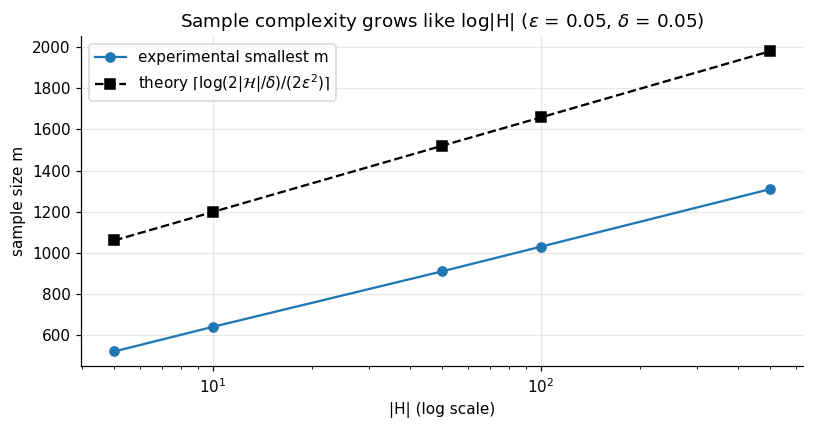

In [7]:
m_fine = np.arange(10, 3001, 10)
rows = []
for K in H_SIZES:
    ps = true_risks(K)
    m_exp = next(m for m in m_fine if exact_uc(m, ps, EPS) <= DELTA)
    p_sim_at, _ = sim_uc_prob(m_exp, ps, EPS, 20_000)
    p_sim_before, _ = sim_uc_prob(m_exp - 10, ps, EPS, 20_000)
    m_th = int(np.ceil(np.log(2 * K / DELTA) / (2 * EPS**2)))
    rows.append((K, m_exp, p_sim_before, p_sim_at, m_th, m_th / m_exp))

print(f"{'|H|':>5} | {'m exp.':>6} | {'P sim at m-10':>13} | {'P sim at m':>10} | {'m theory':>8} | {'theory / exp.':>13}")
for K, me, pb, pa, mt, r in rows:
    print(f"{K:>5} | {me:>6} | {pb:>13.4f} | {pa:>10.4f} | {mt:>8} | {r:>13.2f}")

Ks = np.array(H_SIZES)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(Ks, [r[1] for r in rows], "o-", label="experimental smallest m")
ax.plot(Ks, [r[4] for r in rows], "s--", color="k", label=r"theory $\lceil\log(2|\mathcal{H}|/\delta)/(2\varepsilon^2)\rceil$")
ax.set_xscale("log"); ax.set_xlabel("|H| (log scale)"); ax.set_ylabel("sample size m")
ax.set_title(fr"Sample complexity grows like log|H| ($\varepsilon$ = {EPS}, $\delta$ = {DELTA})"); ax.legend()
plt.tight_layout(); plt.show()


**Observations.**
- For every class size, the **theoretical sample size is valid** (it is larger than the experimental one), but it is **1.5 to 2 times too large**: e.g. $1199$ vs. $640$ for $|\mathcal H|=10$, and $1981$ vs. $1310$ for $|\mathcal H|=500$.
- The simulation confirms the threshold found with the exact probability: at the experimental $m$ the estimated probability is $\le0.051$, and $10$ samples earlier it is $\approx0.05$ or above (within the Monte-Carlo error of about $0.0015$).
- **Both curves grow linearly in $\log|\mathcal H|$** (straight lines on the log-scale plot). The theory captures the right **dependence** on $|\mathcal H|$, but not the right **constant**.
- **Why the bound is only a sufficient guarantee.** It is derived with two inequalities that each lose accuracy (Hoeffding, then the union bound), and it must hold for **every** distribution and **every** set of true risks. For a specific problem the true requirement is smaller. The theoretical value answers "*how many samples are enough in the worst case?*", not "*what is the exact minimum for this problem?*". Using fewer samples than the bound does not imply failure; using at least as many guarantees success.


# Part II — Simulating No-Free-Lunch

Domain $\mathcal X=\{1,\dots,N\}$ with the uniform distribution. In each repetition a **new random task** is drawn: $f(x)\sim\mathrm{Bernoulli}(1/2)$ independently for every $x$. The learner sees $S\sim\mathcal D^m$ (with replacement), predicts the observed label on seen inputs and $0$ on unseen inputs (memorisation learner).

## Task 6 — Seen and unseen inputs

**Theory.** A fixed $x$ is missed by one draw with probability $1-\frac1N$, hence by all $m$ independent draws with probability $(1-\frac1N)^m$. The fraction of unseen inputs is $U=\frac1N\sum_x\mathbb 1[x\text{ unseen}]$, so by **linearity of expectation**
$$\mathbb E[U]=\frac1N\sum_x\Pr[x\text{ unseen}]=\Big(1-\frac1N\Big)^m .$$

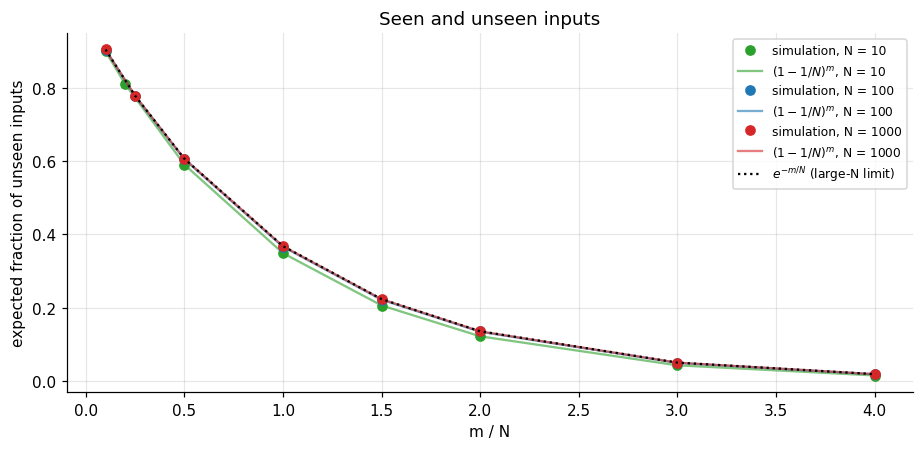

N = 10: m=1: sim 0.900 / th 0.900  m=2: sim 0.810 / th 0.810  m=5: sim 0.589 / th 0.590  m=10: sim 0.349 / th 0.349  m=15: sim 0.203 / th 0.206  m=20: sim 0.123 / th 0.122  m=30: sim 0.043 / th 0.042  m=40: sim 0.014 / th 0.015
N = 100: m=10: sim 0.904 / th 0.904  m=25: sim 0.778 / th 0.778  m=50: sim 0.605 / th 0.605  m=100: sim 0.365 / th 0.366  m=150: sim 0.222 / th 0.221  m=200: sim 0.135 / th 0.134  m=300: sim 0.049 / th 0.049  m=400: sim 0.018 / th 0.018
N = 1000: m=100: sim 0.905 / th 0.905  m=250: sim 0.779 / th 0.779  m=500: sim 0.606 / th 0.606  m=1000: sim 0.368 / th 0.368  m=1500: sim 0.223 / th 0.223  m=2000: sim 0.135 / th 0.135  m=3000: sim 0.050 / th 0.050  m=4000: sim 0.018 / th 0.018


In [8]:
def unseen_fraction(N, m, R=R_II):
    out = np.empty(R)
    for r in range(R):
        seen = np.zeros(N, dtype=bool)
        seen[rng.integers(0, N, size=m)] = True
        out[r] = 1 - seen.mean()
    return out

N_LIST = [10, 100, 1000]
ratios = np.array([0.1, 0.25, 0.5, 1, 1.5, 2, 3, 4])                 # m expressed as a multiple of N
res6 = {}
for N in N_LIST:
    ms = np.unique(np.maximum(1, (ratios * N).astype(int)))
    sim = np.array([unseen_fraction(N, m).mean() for m in ms])
    res6[N] = (ms, sim, (1 - 1 / N) ** ms)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for N, c in zip(N_LIST, ["tab:green", "tab:blue", "tab:red"]):
    ms, sim, th = res6[N]
    ax.plot(ms / N, sim, "o", color=c, label=f"simulation, N = {N}")
    ax.plot(ms / N, th, "-", color=c, alpha=0.6, label=fr"$(1-1/N)^m$, N = {N}")
ax.plot(ratios, np.exp(-ratios), "k:", label=r"$e^{-m/N}$ (large-N limit)")
ax.set_xlabel("m / N"); ax.set_ylabel("expected fraction of unseen inputs")
ax.set_title("Seen and unseen inputs"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for N in N_LIST:
    ms, sim, th = res6[N]
    print(f"N = {N}: " + "  ".join(f"m={m}: sim {s:.3f} / th {t:.3f}" for m, s, t in zip(ms, sim, th)))


**Observations.**
- The simulated fraction of unseen inputs matches $(1-1/N)^m$ to within $0.003$ for every $N$ and $m$ tested.
- **Why it is also the expected fraction.** The fraction of unseen inputs is an average of indicators $\frac1N\sum_x\mathbb 1[x\text{ unseen}]$. By linearity of expectation, its expectation is the average of the probabilities $\Pr[x\text{ unseen}]$, and these are all equal to $(1-1/N)^m$ by symmetry.
- **What matters is the ratio $m/N$.** The three curves are almost identical when plotted against $m/N$ and follow $e^{-m/N}$. With $m=N$ examples, about $37\,\%$ of the domain is still unseen (because of repeated draws). Seeing $95\,\%$ of the domain requires about $m=3N$.
- In particular, with $m\le N/2$ (the No-Free-Lunch regime $m<|\mathcal X|/2$), about **60 %** of the domain is never observed ($e^{-1/2}\approx0.61$).


## Task 7 — Error on unseen inputs

**Derivation.** On a seen input the learner predicts the observed label, which is exactly $f(x)$: no error. On an unseen input it predicts $0$, which is wrong iff $f(x)=1$. Since $f(x)\sim\mathrm{Bernoulli}(1/2)$ is independent of the sample (the sample only reveals labels of **seen** inputs), $\Pr[\text{error at }x\mid x\text{ unseen}]=\tfrac12$. Therefore
$$\mathbb E[L_{\mathcal D}(A(S))]=\frac1N\sum_x\Pr[x\text{ unseen}]\cdot\frac12=\frac12\Big(1-\frac1N\Big)^m .$$

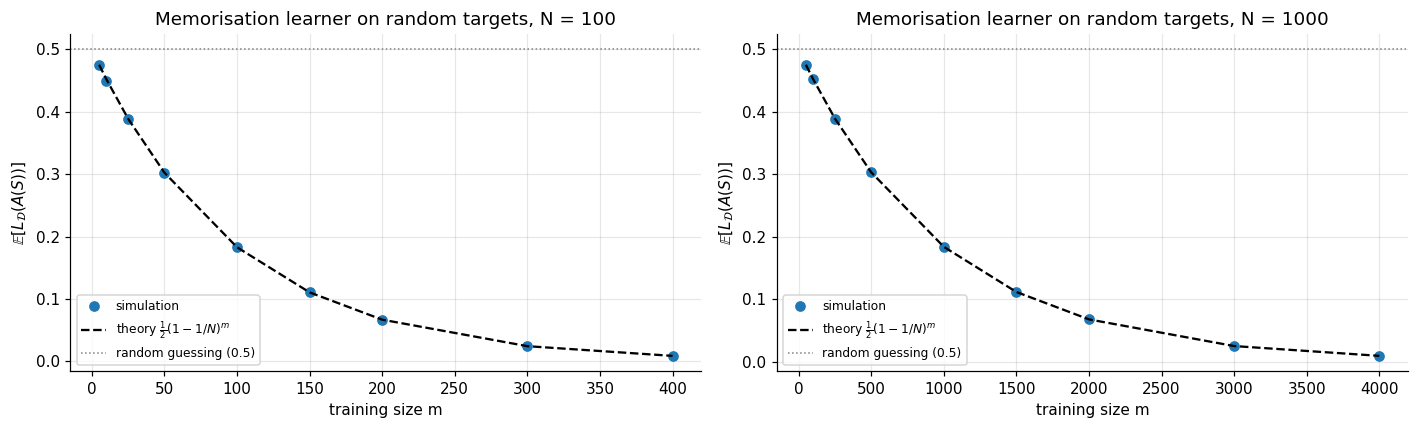

N = 100: max |simulation - theory| = 0.0025
   m=5: 0.476/0.475  m=10: 0.450/0.452  m=25: 0.389/0.389  m=50: 0.303/0.303  m=100: 0.183/0.183  m=150: 0.111/0.111  m=200: 0.067/0.067  m=300: 0.025/0.025  m=400: 0.009/0.009
N = 1000: max |simulation - theory| = 0.0005
   m=50: 0.476/0.476  m=100: 0.453/0.452  m=250: 0.389/0.389  m=500: 0.303/0.303  m=1000: 0.183/0.184  m=1500: 0.111/0.111  m=2000: 0.068/0.068  m=3000: 0.025/0.025  m=4000: 0.009/0.009


In [9]:
def nfl_risk(N, m, rule="zero", R=R_II):
    # True risk of the memorisation learner on random targets; 'rule' = prediction on unseen inputs
    risks = np.empty(R)
    for r in range(R):
        f = rng.integers(0, 2, size=N)
        idx = rng.integers(0, N, size=m)
        seen = np.zeros(N, dtype=bool); seen[idx] = True
        pred = np.where(seen, f, 0)                               # seen inputs: observed label = f(x)
        if rule == "one":
            pred = np.where(seen, f, 1)
        elif rule == "random":
            pred = np.where(seen, f, rng.integers(0, 2, size=N))
        elif rule == "majority":                                   # majority label among observed examples
            maj = int(f[idx].mean() >= 0.5)
            pred = np.where(seen, f, maj)
        risks[r] = np.mean(pred != f)
    return risks

res7 = {}
for N in [100, 1000]:
    ms = np.unique((np.array([0.05, 0.1, 0.25, 0.5, 1, 1.5, 2, 3, 4]) * N).astype(int))
    sim = np.array([nfl_risk(N, m).mean() for m in ms])
    res7[N] = (ms, sim, 0.5 * (1 - 1 / N) ** ms)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, N in zip(axes, [100, 1000]):
    ms, sim, th = res7[N]
    ax.plot(ms, sim, "o", label="simulation")
    ax.plot(ms, th, "k--", label=r"theory $\frac{1}{2}(1-1/N)^m$")
    ax.axhline(0.5, color="gray", ls=":", lw=1, label="random guessing (0.5)")
    ax.set_xlabel("training size m"); ax.set_ylabel(r"$\mathbb{E}[L_\mathcal{D}(A(S))]$")
    ax.set_title(f"Memorisation learner on random targets, N = {N}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for N in [100, 1000]:
    ms, sim, th = res7[N]
    print(f"N = {N}: max |simulation - theory| = {np.max(np.abs(sim - th)):.4f}")
    print("   " + "  ".join(f"m={m}: {s:.3f}/{t:.3f}" for m, s, t in zip(ms, sim, th)))


**Observations.**
- The simulations agree with $\frac12(1-\frac1N)^m$ within $0.0025$ ($N=100$) and $0.0005$ ($N=1000$).
- **The whole error comes from unseen inputs**, where the learner is right exactly half of the time: the training sample carries **no information at all** about the labels of points it does not contain, because those labels are independent coin flips.
- The risk only decreases because the **seen** part of the domain grows. The learner never "generalizes": it only memorizes. With $m=N/2$ the expected risk is still $0.30$, and with $m=N$ it is $0.18$.
- For a huge domain ($N\to\infty$ with $m$ fixed), the risk tends to $1/2$: the learner does no better than random guessing.


## Task 8 — Changing the prediction on unseen inputs

We compare four rules for unseen inputs: always $0$, always $1$, a random Bernoulli$(1/2)$ label, and the **majority label** observed in the training sample (a "clever-looking" heuristic). Targets are still drawn completely at random.

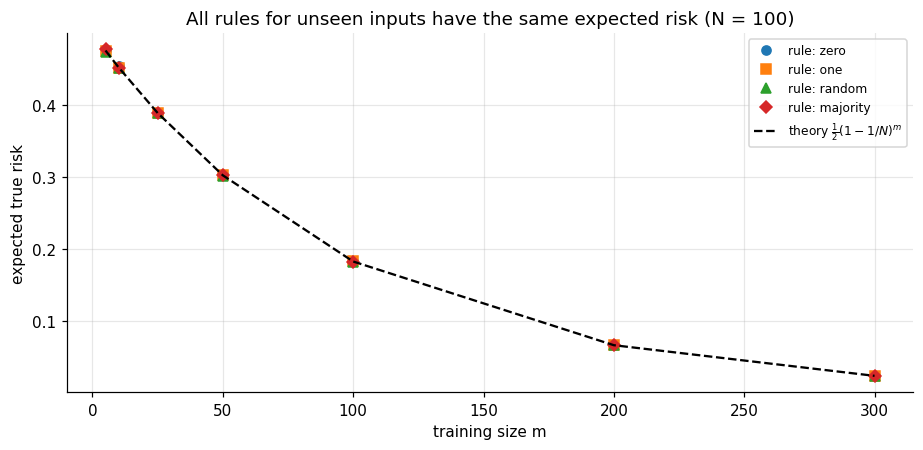

   m |     zero |      one |   random | majority | theory
   5 |   0.4761 |   0.4747 |   0.4735 |   0.4769 | 0.4755
  10 |   0.4535 |   0.4519 |   0.4506 |   0.4519 | 0.4522
  25 |   0.3887 |   0.3887 |   0.3892 |   0.3884 | 0.3889
  50 |   0.3032 |   0.3034 |   0.3018 |   0.3029 | 0.3025
 100 |   0.1837 |   0.1833 |   0.1828 |   0.1828 | 0.1830
 200 |   0.0668 |   0.0669 |   0.0675 |   0.0669 | 0.0670
 300 |   0.0245 |   0.0246 |   0.0245 |   0.0245 | 0.0245


In [10]:
N8 = 100
ms8 = np.array([5, 10, 25, 50, 100, 200, 300])
rules = ["zero", "one", "random", "majority"]
res8 = {rule: np.array([nfl_risk(N8, m, rule).mean() for m in ms8]) for rule in rules}
th8 = 0.5 * (1 - 1 / N8) ** ms8

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for rule, mk in zip(rules, ["o", "s", "^", "D"]):
    ax.plot(ms8, res8[rule], marker=mk, ls="", label=f"rule: {rule}")
ax.plot(ms8, th8, "k--", label=r"theory $\frac{1}{2}(1-1/N)^m$")
ax.set_xlabel("training size m"); ax.set_ylabel("expected true risk")
ax.set_title(f"All rules for unseen inputs have the same expected risk (N = {N8})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'m':>4} | " + " | ".join(f"{r:>8}" for r in rules) + " | theory")
for i, m in enumerate(ms8):
    print(f"{m:>4} | " + " | ".join(f"{res8[r][i]:>8.4f}" for r in rules) + f" | {th8[i]:.4f}")

**Each rule wins on some tasks and loses on others.** To make this visible, we evaluate the "always 0" and "always 1" rules on three *fixed* tasks (all-zero target, all-one target, and a 50/50 target), with $N=100$ and $m=50$.

In [11]:
def fixed_task_risk(f, m, rule, R=R_II):
    N = len(f); risks = np.empty(R)
    for r in range(R):
        seen = np.zeros(N, dtype=bool); seen[rng.integers(0, N, size=m)] = True
        pred = np.where(seen, f, 0 if rule == "zero" else 1)
        risks[r] = np.mean(pred != f)
    return risks.mean()

tasks = {"all zeros": np.zeros(100, int), "all ones": np.ones(100, int),
         "half / half": np.r_[np.zeros(50, int), np.ones(50, int)]}
print(f"{'task':<12} | {'rule zero':>9} | {'rule one':>8}")
for name, f in tasks.items():
    print(f"{name:<12} | {fixed_task_risk(f, 50, 'zero'):>9.4f} | {fixed_task_risk(f, 50, 'one'):>8.4f}")
print(f"{'average':<12} | {np.mean([fixed_task_risk(f, 50, 'zero') for f in tasks.values()]):>9.4f} | "
      f"{np.mean([fixed_task_risk(f, 50, 'one') for f in tasks.values()]):>8.4f}")

task         | rule zero | rule one
all zeros    |    0.0000 |   0.6045
all ones     |    0.6049 |   0.0000


half / half  |    0.3030 |   0.3028
average      |    0.3022 |   0.3023



**Observations.**
- **No rule outperforms the others.** For every $m$, the four rules (always 0, always 1, random, and even the "clever" majority vote) have the same expected risk, equal to the theoretical $\frac12(1-1/N)^m$ up to Monte-Carlo noise (differences $\le0.002$).
- The reason: averaged over all possible targets, an unseen label is $0$ or $1$ with probability $1/2$, **whatever the rule predicts**. Even the majority vote cannot help, since the observed labels say nothing about the unseen ones.
- **Each rule wins on some tasks and loses on others.** "Always 0" is perfect on unseen inputs of the all-zero task (risk $0$) but poor on the all-one task (risk $0.60$); "always 1" does exactly the opposite. Averaged over tasks, both are identical ($0.302$ vs. $0.302$).
- **Link with No-Free-Lunch.** This is exactly the message of the theorem: no learning algorithm is better than another **over all possible tasks**. A rule can only be better on a family of tasks if it encodes an assumption favouring that family, and it then pays for it on the other tasks.


# Part III — Introducing prior knowledge

The target is now a **threshold** $f_\theta(x)=\mathbb 1[x>\theta]$ with $\theta$ drawn uniformly in $\{1,\dots,N-1\}$ at each repetition, and the learner uses ERM over the matching class $\mathcal H=\{h_t(x)=\mathbb 1[x>t] : t\in\{1,\dots,N-1\}\}$.

**ERM implementation.** For each candidate $t$, the number of training mistakes is
$$\mathrm{err}(t)=\#\{i: x_i\le t,\ y_i=1\}+\#\{i: x_i>t,\ y_i=0\},$$
computed for all $t$ at once with cumulative sums over the domain ($O(N+m)$). Since the target is a threshold, at least one $t$ has zero error (realizable case). When several thresholds tie, we take the **median** of the optimal ones, i.e. a threshold in the middle of the gap between the largest observed negative and the smallest observed positive. The true risk over the whole domain is the fraction of inputs where $h_{\hat t}$ and $f_\theta$ disagree, $|\hat t-\theta|/N$.

In [12]:
def erm_threshold_discrete(x, y, N):
    # Exact ERM over thresholds t in {1..N-1}; x in {1..N}. Returns t_hat.
    pos = np.bincount(x, weights=(y == 1), minlength=N + 1)          # positives at each value
    neg = np.bincount(x, weights=(y == 0), minlength=N + 1)          # negatives at each value
    pos_le = np.cumsum(pos)                                          # positives with x <= t
    neg_gt = neg.sum() - np.cumsum(neg)                              # negatives with x > t
    t = np.arange(1, N)
    err = pos_le[t] + neg_gt[t]
    best = t[err == err.min()]
    return best[len(best) // 2]

def threshold_experiment(N, m, R=R_II, unseen_only=False):
    risks = np.empty(R); unseen_err = []
    domain = np.arange(1, N + 1)
    for r in range(R):
        theta = rng.integers(1, N)                                    # theta in {1..N-1}
        f = (domain > theta).astype(int)
        x = rng.integers(1, N + 1, size=m); y = (x > theta).astype(int)
        t_hat = erm_threshold_discrete(x, y, N)
        pred = (domain > t_hat).astype(int)
        risks[r] = np.mean(pred != f)
        seen = np.zeros(N + 1, dtype=bool); seen[x] = True
        uns = ~seen[1:]
        if uns.any():
            unseen_err.append(np.mean(pred[uns] != f[uns]))
    return risks, np.array(unseen_err)

# sanity check: ERM always reaches zero training error
chk = np.random.default_rng(7); ok = 0
for _ in range(500):
    N, m = 100, chk.integers(1, 200); th = chk.integers(1, N)
    x = chk.integers(1, N + 1, size=m); y = (x > th).astype(int)
    t = erm_threshold_discrete(x, y, N); ok += np.all((x > t).astype(int) == y)
print(f"Runs where ERM reaches zero training error: {ok}/500")

Runs where ERM reaches zero training error: 500/500


## Task 9 — Learning with a matching inductive bias

In [13]:
res9 = {}
for N in [100, 1000]:
    ms = res7[N][0]
    sims = [threshold_experiment(N, m) for m in ms]
    res9[N] = (ms, np.array([s[0].mean() for s in sims]), np.array([s[1].mean() for s in sims]))

print(f"{'N':>5} {'m':>5} | {'E[L_D] threshold ERM':>20} | {'E[L_D] random targets (Part II)':>31} | {'error on unseen (threshold)':>27}")
for N in [100, 1000]:
    ms, thr, uns = res9[N]
    for i, m in enumerate(ms):
        print(f"{N:>5} {m:>5} | {thr[i]:>20.4f} | {res7[N][1][i]:>31.4f} | {uns[i]:>27.4f}")

    N     m | E[L_D] threshold ERM | E[L_D] random targets (Part II) | error on unseen (threshold)
  100     5 |               0.0701 |                          0.4755 |                      0.0737
  100    10 |               0.0426 |                          0.4497 |                      0.0471
  100    25 |               0.0184 |                          0.3885 |                      0.0236
  100    50 |               0.0089 |                          0.3027 |                      0.0146
  100   100 |               0.0042 |                          0.1827 |                      0.0114
  100   150 |               0.0023 |                          0.1113 |                      0.0105
  100   200 |               0.0014 |                          0.0668 |                      0.0102
  100   300 |               0.0004 |                          0.0247 |                      0.0086
  100   400 |               0.0001 |                          0.0094 |                      0.0074
 1000    5


**Observations.**
- With threshold targets and threshold ERM, the expected true risk is tiny and decreases quickly. For $N=100$: $0.070$ at $m=5$, $0.009$ at $m=50$, $0.004$ at $m=100$. For $N=1000$: $0.0047$ at $m=100$ and $0.0004$ at $m=1000$.
- **Comparison with Part II** (same $N$, same $m$): with random targets the risk is $0.30$ at $m=N/2$ and still $0.18$ at $m=N$. With threshold targets it is already about **7 times smaller with only 5 examples**, and **30 to 450 times smaller** once $m\ge50$, for the same amount of data.
- **The decisive difference: unseen inputs.** For random targets the error on unseen inputs is $1/2$ for any rule. For threshold targets it is only about $1\,\%$ for $N=100$ and $0.1$–$1\,\%$ for $N=1000$. The learner now predicts **correctly the labels of inputs it has never seen**.
- The risk decreases roughly like $1/m$ (e.g. $0.0095\to0.0047\to0.0020\to0.0010$ for $m=50,100,250,500$ with $N=1000$). This is the fast realizable rate: the only uncertainty is where exactly $\theta$ lies between the closest observed negative and positive.


## Task 10 — Random targets vs. structured targets

We compare the evolution of the true risk with $m$ in both settings. To isolate the role of the inductive bias, we also run the two **mismatched** combinations: the memorisation learner on threshold targets, and threshold ERM on random targets.

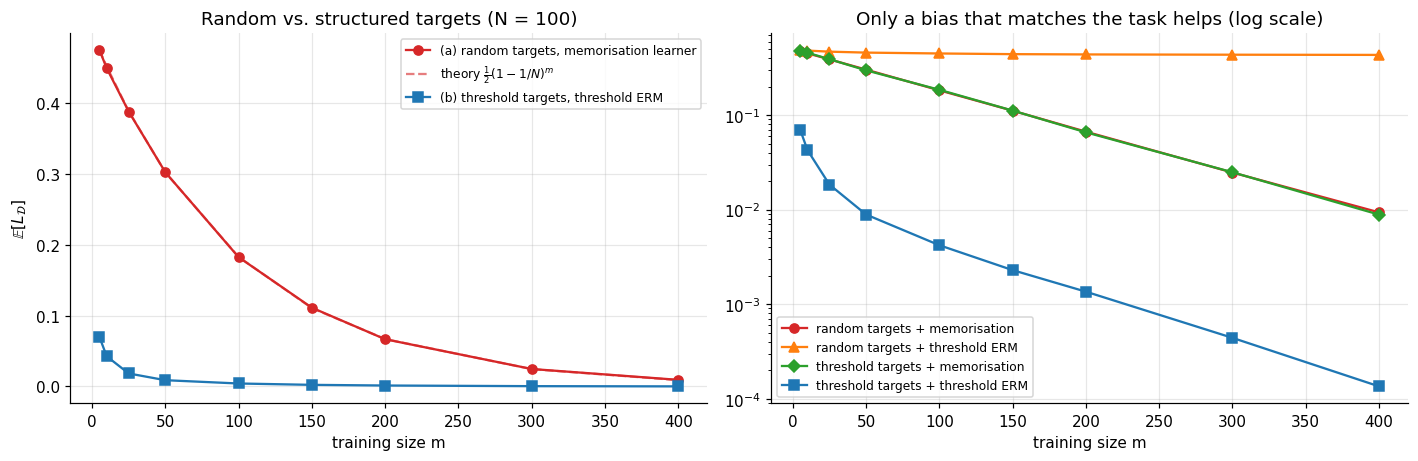

   m | rand+memo | rand+thrERM | thr+memo | thr+thrERM
   5 |    0.4755 |      0.4882 |   0.4711 |     0.0701
  10 |    0.4497 |      0.4812 |   0.4568 |     0.0426
  25 |    0.3885 |      0.4688 |   0.3900 |     0.0184
  50 |    0.3027 |      0.4580 |   0.2974 |     0.0089
 100 |    0.1827 |      0.4485 |   0.1851 |     0.0042
 150 |    0.1113 |      0.4412 |   0.1115 |     0.0023
 200 |    0.0668 |      0.4381 |   0.0657 |     0.0014
 300 |    0.0247 |      0.4352 |   0.0248 |     0.0004
 400 |    0.0094 |      0.4331 |   0.0089 |     0.0001


In [14]:
def memo_on_threshold(N, m, R=R_II):
    risks = np.empty(R); domain = np.arange(1, N + 1)
    for r in range(R):
        theta = rng.integers(1, N); f = (domain > theta).astype(int)
        seen = np.zeros(N, dtype=bool); seen[rng.integers(0, N, size=m)] = True
        risks[r] = np.mean(np.where(seen, f, 0) != f)
    return risks.mean()

def threshold_on_random(N, m, R=R_II):
    risks = np.empty(R); domain = np.arange(1, N + 1)
    for r in range(R):
        f = rng.integers(0, 2, size=N)
        x = rng.integers(1, N + 1, size=m); y = f[x - 1]
        t = erm_threshold_discrete(x, y, N)
        risks[r] = np.mean((domain > t).astype(int) != f)
    return risks.mean()

N10 = 100
ms10 = res7[N10][0]
memo_thr = np.array([memo_on_threshold(N10, m) for m in ms10])
thr_rand = np.array([threshold_on_random(N10, m) for m in ms10])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(ms10, res7[N10][1], "o-", color="tab:red", label="(a) random targets, memorisation learner")
ax.plot(ms10, res7[N10][2], "--", color="tab:red", alpha=0.6, label=r"theory $\frac{1}{2}(1-1/N)^m$")
ax.plot(ms10, res9[N10][1], "s-", color="tab:blue", label="(b) threshold targets, threshold ERM")
ax.set_xlabel("training size m"); ax.set_ylabel(r"$\mathbb{E}[L_\mathcal{D}]$")
ax.set_title(f"Random vs. structured targets (N = {N10})"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(ms10, res7[N10][1], "o-", color="tab:red", label="random targets + memorisation")
ax.plot(ms10, thr_rand, "^-", color="tab:orange", label="random targets + threshold ERM")
ax.plot(ms10, memo_thr, "D-", color="tab:green", label="threshold targets + memorisation")
ax.plot(ms10, res9[N10][1], "s-", color="tab:blue", label="threshold targets + threshold ERM")
ax.set_yscale("log"); ax.set_xlabel("training size m")
ax.set_title("Only a bias that matches the task helps (log scale)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'m':>4} | {'rand+memo':>9} | {'rand+thrERM':>11} | {'thr+memo':>8} | {'thr+thrERM':>10}")
for i, m in enumerate(ms10):
    print(f"{m:>4} | {res7[N10][1][i]:>9.4f} | {thr_rand[i]:>11.4f} | {memo_thr[i]:>8.4f} | {res9[N10][1][i]:>10.4f}")

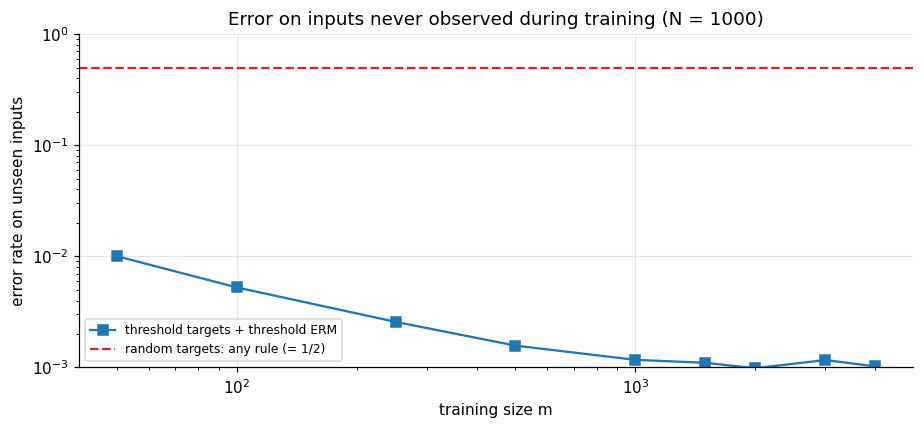

In [15]:
# Error restricted to UNSEEN inputs: the heart of the matter
ms_u = res9[1000][0]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(ms_u, res9[1000][2], "s-", color="tab:blue", label="threshold targets + threshold ERM")
ax.axhline(0.5, color="tab:red", ls="--", label="random targets: any rule (= 1/2)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-3, 1)
ax.set_xlabel("training size m"); ax.set_ylabel("error rate on unseen inputs")
ax.set_title("Error on inputs never observed during training (N = 1000)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Observations.**
- **Random targets** (red): the risk follows $\frac12(1-1/N)^m$ and only decreases by covering the domain. **Structured targets with a matching class** (blue): the risk is small from the very first examples.
- **The role of the threshold assumption.** Knowing that the target belongs to $\{\mathbb 1[x>t]\}$, a few labelled points determine the labels of **whole intervals**. Every point left of an observed negative must be negative, and every point right of an observed positive must be positive. The only uncertain region is the gap between the largest observed negative and the smallest observed positive, which shrinks like $N/m$. One labelled example therefore gives information about many unseen inputs. This is impossible with random targets, where each label is independent of all others.
- **The bias must match the task** (right plot):
  - *threshold targets + memorisation learner*: the risk is identical to the random case ($0.30$ at $m=50$), because the learner ignores the structure;
  - *random targets + threshold ERM*: the risk stays around $0.43$–$0.49$ even with $m=4N$, because a threshold cannot represent an arbitrary labelling (large approximation error);
  - only *threshold targets + threshold ERM* generalizes ($0.009$ at $m=50$).
- **Prior knowledge is useful only when it is correct.** The restriction to thresholds is an inductive bias: it is exactly what lets the learner generalize here, and exactly what makes it fail on arbitrary tasks.



## 11. Final analysis

| Experiment | Main observation | Theoretical counterpart |
|---|---|---|
| Task 1 | $L_S(h)$ is centred on $L_{\mathcal D}(h)$, with spread $\sqrt{p(1-p)/m}$ | unbiased estimator, CLT, $1/\sqrt m$ concentration |
| Tasks 2–3 | deviation probabilities decay exponentially; the bounds are valid but 5–16 times too large | Hoeffding $2e^{-2m\varepsilon^2}$, union bound $2|\mathcal H|e^{-2m\varepsilon^2}$ |
| Tasks 4–5 | 100 times more hypotheses $\Rightarrow$ only about 2.5 times more data; the bound overestimates $m$ by 1.5–2 | $m\ge\log(2|\mathcal H|/\delta)/(2\varepsilon^2)$ |
| Tasks 6–8 | random targets: error $\tfrac12$ on every unseen input, whatever the rule | No-Free-Lunch |
| Tasks 9–10 | threshold targets + threshold class: about 1 % error on unseen inputs | inductive bias, realizable PAC learning |

- **Why $L_S(h)$ concentrates around $L_{\mathcal D}(h)$.** For a fixed $h$, $L_S(h)$ is an average of $m$ independent losses whose mean is $L_{\mathcal D}(h)$. Averaging cancels out the randomness: the variance is $p(1-p)/m$ and large deviations become exponentially unlikely (Tasks 1–2).
- **Why uniform convergence needs simultaneous control.** ERM chooses its hypothesis **after** looking at the sample, so we cannot know in advance which $h$ will be selected. The guarantee $L_{\mathcal D}(h_S)\le\min_hL_{\mathcal D}(h)+\varepsilon$ requires the sample to be representative for **every** $h$ at once. Task 3 showed that this is much harder than for one hypothesis: one unlucky hypothesis is enough to break it.
- **Effect of $|\mathcal H|$.** More hypotheses means more chances that one is fooled, so more data is needed (Task 4). The cost is only logarithmic: multiplying $|\mathcal H|$ by 100 raised the experimental sample complexity from 520 to 1310 (Task 5).
- **Why the bounds are conservative.** Hoeffding ignores the actual variance, the union bound ignores the overlap between bad events and the differences between hypotheses, and both must hold for every distribution. They are **sufficient** guarantees, about 1.5–2 times larger than the experimental requirement here.
- **Why random targets make unseen labels unpredictable.** When each label is an independent coin flip, the training sample contains no information about unseen inputs. Any prediction is correct with probability exactly $1/2$ (Tasks 7–8).
- **No-Free-Lunch.** All prediction rules for unseen inputs have the same expected risk $\frac12(1-1/N)^m$ over random tasks, and each rule is excellent on some tasks and poor on others. A learner cannot infer arbitrary unseen labels from the training sample alone: without assumptions, the only way to reduce the error is to observe (almost) the whole domain.
- **Prior knowledge.** Restricting both the targets and the hypotheses to thresholds encodes the assumption that labels change only once along the domain. This **inductive bias** turns each labelled example into information about whole intervals of unseen inputs, which is why the error on unseen inputs drops from 50 % to about 1 % (Tasks 9–10).
- **The bias must be right.** The same threshold learner fails on random targets (about 45 % error), and the memorisation learner gains nothing from the threshold structure. Generalization comes from a **match** between the assumptions built into the learner and the true task, exactly as the No-Free-Lunch theorem and the bias-complexity tradeoff predict.


## References

1. A. Ismail-Fawaz. *Statistical and Machine Learning*, lecture slides, Sessions 3–4 (Learning via Uniform Convergence; The Bias-Complexity Tradeoff). Université de Haute-Alsace.
2. S. Shalev-Shwartz and S. Ben-David (2014). *Understanding Machine Learning: From Theory to Algorithms*. Cambridge University Press, Chapters 4–5.
3. W. Hoeffding (1963). Probability inequalities for sums of bounded random variables. *Journal of the American Statistical Association*, 58(301), 13–30.
4. D. H. Wolpert (1996). The lack of a priori distinctions between learning algorithms. *Neural Computation*, 8(7), 1341–1390.